# 05 — Previsão de 2024 (Etapa B)

**Trabalho 2 – Previsão do PIB dos Municípios da Região Sul (PR, SC, RS)**

Objetivo: **retreinar os modelos com os dados até 2023** e prever, para os 1.191 municípios da região, o **PIB de 2024** e a **categoria de crescimento de 2024**.

## Como os modelos da Etapa B são escolhidos

Na Etapa A (notebooks 03 e 04), 2023 ficou fora de toda escolha e serviu só como teste. Na Etapa B, o PIB oficial de 2023 já é conhecido, então ele **entra na validação**.
Repetimos o **mesmo protocolo** das fases anteriores, agora com 5 anos de validação (2019 a 2023):

| Tarefa | Protocolo | Onde |
|---|---|---|
| Regressão | busca de hiperparâmetros (alvos a partir de 2013) e escolha conjunta de (modelo, janela) pelo menor MAPE médio | seção 1 deste notebook |
| Classificação | o mesmo, pelo maior F1 macro médio | seção 7 do notebook 04 (`config_classificacao_etapa_b.json`) |

Depois, cada modelo escolhido é **retreinado com todos os alvos da sua janela até 2023** e prevê 2024.
As variáveis de 2024 usadas na previsão já estavam publicadas: PIB municipal até 2023, PAM, PPM e estimativa de população de 2024, e PIA e PAS das UFs (notebook 01).

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import features as ft
from src import modelos as m
from src import viz

viz.aplica_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

DIR_RES = RAIZ / "reports" / "resultados"
DIR_PRED = RAIZ / "data" / "predictions"
CATS = ft.CATEGORIAS
ANOS_B = m.ANOS_VALIDACAO_ETAPA_B
INICIO_PADRAO = ft.PRIMEIRO_ANO_AMOSTRA_PADRAO

dataset = ft.carrega_dataset()
numericas, categoricas = ft.colunas_modelo(dataset)
alvo_2024 = dataset[dataset["conjunto"] == "previsao_2024"].copy()
assert len(alvo_2024) == 1191 and alvo_2024["pib_l1"].notna().all()
assert alvo_2024[numericas].notna().all().all()
print(f"Municípios a prever: {len(alvo_2024)} | anos de validação da Etapa B: {ANOS_B}")

Municípios a prever: 1191 | anos de validação da Etapa B: [2019, 2020, 2021, 2022, 2023]


## 1. Escolha da regressão para a Etapa B (validação 2019–2023)

In [2]:
t0 = time.time()
buscas_b = {}
for nome in m.FABRICAS_REGRESSAO:
    buscas_b[nome] = m.busca_hiperparametros(nome, dataset, INICIO_PADRAO, anos_validacao=ANOS_B, verbose=False)
    print(f"{nome}: {buscas_b[nome].iloc[0]['params']} -> MAPE médio {buscas_b[nome].iloc[0]['MAPE_%']:.2f}%")
melhores_b = {nome: tab.iloc[0]["params"] for nome, tab in buscas_b.items()}
params_reg_b = {**melhores_b, m.NOME_ENSEMBLE: {c: melhores_b[c] for c in m.COMPONENTES_ENSEMBLE}}

res_janelas = {}
for inicio in [2010, 2013, 2016]:
    for nome, p in params_reg_b.items():
        res_janelas[(nome, inicio)] = m.valida_temporal(nome, p, dataset, inicio, anos_validacao=ANOS_B)
tab_janelas = pd.Series({k: r.media["MAPE_%"] for k, r in res_janelas.items()}).unstack()
melhor_reg, inicio_reg = tab_janelas.stack().idxmin()
inicio_reg = int(inicio_reg)
print(f"Tempo: {(time.time() - t0) / 60:.1f} min")
print(f"Regressão da Etapa B: {melhor_reg} com alvos a partir de {inicio_reg} (MAPE médio 2019–2023 = {tab_janelas.min().min():.2f}%)")
tab_janelas.columns = [f"início {c}" for c in tab_janelas.columns]
tab_janelas.round(2)

Ridge: {'alpha': 1000} -> MAPE médio 9.15%


Huber: {'alpha': 1, 'epsilon': 2.0} -> MAPE médio 9.79%


Random Forest: {'min_samples_leaf': 5, 'max_features': 0.6} -> MAPE médio 7.61%


LightGBM: {'objective': 'l1', 'num_leaves': 15, 'min_child_samples': 20, 'colsample_bytree': 0.6, 'subsample': 0.8, 'reg_lambda': 5.0} -> MAPE médio 7.36%


Tempo: 5.8 min
Regressão da Etapa B: Ensemble (Ridge + RF + LightGBM) com alvos a partir de 2016 (MAPE médio 2019–2023 = 7.16%)


,início 2010,início 2013,início 2016
Ensemble (Ridge + RF + LightGBM),7.530,7.580,7.160
Huber,8.660,9.790,9.310
LightGBM,7.320,7.360,7.440
Random Forest,7.700,7.610,7.470
Ridge,8.550,9.150,8.450


In [3]:
por_ano_reg = pd.DataFrame({f"{nome} (início {ini})": r.por_ano["MAPE_%"] for (nome, ini), r in res_janelas.items()
                            if ini == inicio_reg}).T
por_ano_reg["média"] = por_ano_reg.mean(axis=1)
por_ano_reg = por_ano_reg.sort_values("média")
por_ano_reg.to_csv(DIR_RES / "regressao_validacao_etapa_b.csv")

config_reg_b = {"melhor_modelo": melhor_reg, "inicio_janela": inicio_reg, "hiperparametros": params_reg_b,
                "criterio": "MAPE médio na validação temporal 2019–2023 (Etapa B)"}
_ = (DIR_RES / "config_regressao_etapa_b.json").write_text(json.dumps(config_reg_b, indent=2, ensure_ascii=False), encoding="utf-8")

config_clf_b = json.loads((DIR_RES / "config_classificacao_etapa_b.json").read_text(encoding="utf-8"))
melhor_clf, inicio_clf = config_clf_b["melhor_modelo"], config_clf_b["inicio_janela"]
params_clf = config_clf_b["hiperparametros"][melhor_clf]
print(f"Classificação da Etapa B (notebook 04): {melhor_clf} com alvos a partir de {inicio_clf}")
por_ano_reg.round(2)

Classificação da Etapa B (notebook 04): Regressão → categoria (Ensemble) com alvos a partir de 2013


ano_validacao,2019,2020,2021,2022,2023,média
Ensemble (Ridge + RF + LightGBM) (início 2016),4.810,6.160,8.460,9.470,6.920,7.160
LightGBM (início 2016),4.860,6.520,9.640,9.080,7.110,7.440
Random Forest (início 2016),4.940,6.380,9.730,9.240,7.050,7.470
Ridge (início 2016),4.810,5.970,12.490,11.680,7.290,8.450
Huber (início 2016),4.890,10.190,13.760,11.110,6.590,9.310


## 2. Incerteza: intervalo empírico de 80% para o PIB

O modelo dá uma estimativa pontual. Para dar uma ideia da incerteza, usamos os **erros do próprio modelo na validação 2019–2023**: para cada ano v, o modelo treinado até v-1 prevê v, e guardamos o erro em log, `log(PIB real / PIB previsto)`.
Os percentis 10 e 90 desses erros, **separados por porte do município** (os pequenos erram mais, notebook 03), viram um intervalo em torno da previsão de 2024.
O intervalo é aproximado: assume que o erro de 2024 se parece com o dos últimos 5 anos.

In [4]:
FAIXA_PORTE = {"ate_5mil": "até 10 mil hab.", "5_10mil": "até 10 mil hab.", "10_20mil": "10 a 50 mil hab.",
               "20_50mil": "10 a 50 mil hab.", "50_100mil": "acima de 50 mil hab.",
               "100_500mil": "acima de 50 mil hab.", "acima_500mil": "acima de 50 mil hab."}

residuos = []
for v in ANOS_B:
    tr = m.amostra_modelagem(dataset, inicio_reg, v - 1)
    va = m.amostra_modelagem(dataset, v, v)
    g, _ = m.treina_preve_modelo(melhor_reg, params_reg_b[melhor_reg], tr, va, numericas, categoricas)
    residuos.append(pd.DataFrame({"ano": v, "faixa": va["porte"].astype(str).map(FAIXA_PORTE).to_numpy(),
                                  "erro_log": va["cresc_pib_log"].to_numpy() - g}))
residuos = pd.concat(residuos, ignore_index=True)
quantis = residuos.groupby("faixa")["erro_log"].quantile([0.10, 0.90]).unstack()
quantis.columns = ["q10", "q90"]
quantis["intervalo_80_%"] = [f"{(np.exp(a) - 1) * 100:+.1f}% a {(np.exp(b) - 1) * 100:+.1f}%" for a, b in zip(quantis.q10, quantis.q90)]
quantis["casos"] = residuos.groupby("faixa").size()
quantis

,q10,q90,intervalo_80_%,casos
faixa,,,,
10 a 50 mil hab.,-0.094,0.103,-9.0% a +10.9%,1901
acima de 50 mil hab.,-0.070,0.093,-6.7% a +9.7%,554
até 10 mil hab.,-0.124,0.112,-11.6% a +11.8%,3500


## 3. Retreino com os dados até 2023 e previsão de 2024

In [5]:
# PIB: modelo de regressão da Etapa B, treinado com alvos de inicio_reg a 2023
treino_reg = m.amostra_modelagem(dataset, inicio_reg, 2023)
g_pib, modelo_pib = m.treina_preve_modelo(melhor_reg, params_reg_b[melhor_reg], treino_reg, alvo_2024, numericas, categoricas)
print(f"Regressão: {len(treino_reg):,} linhas de treino (alvos {treino_reg['ano'].min()}–{treino_reg['ano'].max()})")

# Categoria: modelo de classificação da Etapa B, treinado com alvos de inicio_clf a 2023
treino_clf = m.amostra_modelagem(dataset, inicio_clf, 2023)
if melhor_clf == m.NOME_REG_CATEGORIA:
    g_cat, _ = m.treina_preve_modelo(m.NOME_ENSEMBLE, params_clf, treino_clf, alvo_2024, numericas, categoricas)
    cat_2024 = m.categoria_de_log(g_cat)
else:
    g_cat = np.full(len(alvo_2024), np.nan)
    cat_2024 = m.preve_categoria(melhor_clf, params_clf, treino_clf, alvo_2024, numericas, categoricas)
print(f"Classificação: {len(treino_clf):,} linhas de treino (alvos {treino_clf['ano'].min()}–{treino_clf['ano'].max()})")

prev = alvo_2024[["cod_ibge", "municipio", "uf", "regiao_intermediaria", "porte", "pib_l1"]].copy()
prev["faixa_porte"] = prev["porte"].astype(str).map(FAIXA_PORTE)
prev["pib_2024_prev"] = prev["pib_l1"] * np.exp(g_pib)
prev["cresc_2024_prev_pct"] = (np.exp(g_pib) - 1) * 100
q = quantis.loc[prev["faixa_porte"]]
prev["pib_2024_lim_inf_80"] = prev["pib_2024_prev"] * np.exp(q["q10"].to_numpy())
prev["pib_2024_lim_sup_80"] = prev["pib_2024_prev"] * np.exp(q["q90"].to_numpy())
prev["cat_implicita_pib"] = m.categoria_de_log(g_pib)
prev["cat_2024"] = cat_2024
prev["cresc_2024_modelo_categoria_pct"] = (np.exp(g_cat) - 1) * 100
assert prev["pib_2024_prev"].notna().all() and (prev["pib_2024_prev"] > 0).all()
prev[["municipio", "uf", "pib_l1", "pib_2024_prev", "cresc_2024_prev_pct", "pib_2024_lim_inf_80", "pib_2024_lim_sup_80"]].head()

Regressão: 9,528 linhas de treino (alvos 2016–2023)


Classificação: 13,098 linhas de treino (alvos 2013–2023)


,municipio,uf,pib_l1,pib_2024_prev,cresc_2024_prev_pct,pib_2024_lim_inf_80,pib_2024_lim_sup_80
16,Abatiá,PR,"297,166.000","273,017.546",-8.126,"241,249.565","305,304.991"
33,Adrianópolis,PR,"467,129.000","481,735.616",3.127,"425,681.462","538,706.358"
50,Agudos do Sul,PR,"279,388.000","274,839.608",-1.628,"250,161.334","304,718.987"
67,Almirante Tamandaré,PR,"2,242,620.000","2,402,775.555",7.141,"2,240,726.824","2,636,621.538"
84,Altamira do Paraná,PR,"115,509.000","117,023.660",1.311,"103,406.933","130,863.045"


### 3.1 Coerência entre o PIB previsto e a categoria prevista

O PIB vem do modelo de regressão e a categoria do modelo de classificação, cada um escolhido pela sua métrica e com a sua janela de treino.
Medimos em quantos municípios a categoria prevista é a mesma que o PIB previsto indicaria.

In [6]:
concorda = (prev["cat_2024"] == prev["cat_implicita_pib"])
dist_cat = np.abs(prev["cat_2024"] - prev["cat_implicita_pib"])
print(f"Mesma categoria: {concorda.mean() * 100:.1f}% dos municípios | diferença de 1 categoria: {(dist_cat == 1).mean() * 100:.1f}% "
      f"| 2 ou mais: {(dist_cat >= 2).mean() * 100:.1f}%")
if melhor_clf == m.NOME_REG_CATEGORIA:
    dif = prev["cresc_2024_modelo_categoria_pct"] - prev["cresc_2024_prev_pct"]
    print(f"Diferença entre os crescimentos previstos pelas duas janelas: mediana {dif.median():+.2f} pp, "
          f"90% dos municípios entre {dif.quantile(0.05):+.2f} e {dif.quantile(0.95):+.2f} pp")
pd.crosstab(pd.Categorical.from_codes(prev["cat_implicita_pib"], CATS, ordered=True),
            pd.Categorical.from_codes(prev["cat_2024"], CATS, ordered=True),
            rownames=["categoria pelo PIB previsto"], colnames=["categoria prevista"])

Mesma categoria: 82.4% dos municípios | diferença de 1 categoria: 16.5% | 2 ou mais: 1.2%
Diferença entre os crescimentos previstos pelas duas janelas: mediana -0.11 pp, 90% dos municípios entre -2.60 e +2.33 pp


categoria prevista,Forte retração,Retração,Estabilidade,Crescimento moderado,Forte crescimento
categoria pelo PIB previsto,,,,,
Forte retração,188,4,0,0,0
Retração,12,83,9,1,0
Estabilidade,1,34,28,14,0
Crescimento moderado,0,8,44,114,14
Forte crescimento,0,2,2,65,568


## 4. Arquivos de previsão

* `data/predictions/previsoes_pib_2024.csv`: PIB previsto para 2024 com o intervalo empírico de 80%;
* `data/predictions/previsoes_categoria_2024.csv`: categoria de crescimento prevista para 2024;
* `data/predictions/previsoes_2023_validacao.csv`: Etapa A, com o previsto (treino até 2022) contra o oficial de 2023.

Valores de PIB em **mil reais**, a preços correntes, como no IBGE.

In [7]:
DIR_PRED.mkdir(parents=True, exist_ok=True)
nome_cat = lambda c: pd.Categorical.from_codes(c, CATS, ordered=True)

saida_pib = pd.DataFrame({
    "cod_ibge": prev["cod_ibge"], "municipio": prev["municipio"], "uf": prev["uf"],
    "pib_2023_oficial_mil_reais": prev["pib_l1"].round(0),
    "pib_2024_previsto_mil_reais": prev["pib_2024_prev"].round(0),
    "pib_2024_limite_inferior_80_mil_reais": prev["pib_2024_lim_inf_80"].round(0),
    "pib_2024_limite_superior_80_mil_reais": prev["pib_2024_lim_sup_80"].round(0),
    "crescimento_2024_previsto_pct": prev["cresc_2024_prev_pct"].round(2),
    "modelo": f"{melhor_reg}, alvos {inicio_reg}–2023",
})
saida_cat = pd.DataFrame({
    "cod_ibge": prev["cod_ibge"], "municipio": prev["municipio"], "uf": prev["uf"],
    "categoria_2024_prevista": nome_cat(prev["cat_2024"]),
    "crescimento_2024_modelo_categoria_pct": prev["cresc_2024_modelo_categoria_pct"].round(2),
    "categoria_pelo_pib_previsto": nome_cat(prev["cat_implicita_pib"]),
    "modelo": f"{melhor_clf}, alvos {inicio_clf}–2023",
})

# Etapa A: previsões de 2023 (treino até 2022) dos modelos escolhidos sem ver 2023
reg23 = pd.read_csv(DIR_PRED / "regressao_teste_2023_todos_modelos.csv")
clf23 = pd.read_csv(DIR_PRED / "classificacao_teste_2023_todos_modelos.csv")
config_reg_a = json.loads((DIR_RES / "config_regressao.json").read_text(encoding="utf-8"))
config_clf_a = json.loads((DIR_RES / "config_classificacao.json").read_text(encoding="utf-8"))
assert config_reg_a["melhor_modelo"] == m.NOME_ENSEMBLE and config_clf_a["melhor_modelo"] == "Random Forest (clf)"
val23 = reg23[["cod_ibge", "municipio", "uf", "pib_l1", "pib", "pib_prev_ensemble", "categoria_crescimento"]].merge(
    clf23[["cod_ibge", "cat_prev_random_forest"]], on="cod_ibge", validate="1:1")
saida_23 = pd.DataFrame({
    "cod_ibge": val23["cod_ibge"], "municipio": val23["municipio"], "uf": val23["uf"],
    "pib_2023_oficial_mil_reais": val23["pib"].round(0),
    "pib_2023_previsto_mil_reais": val23["pib_prev_ensemble"].round(0),
    "erro_pct": ((val23["pib_prev_ensemble"] / val23["pib"] - 1) * 100).round(2),
    "categoria_2023_oficial": val23["categoria_crescimento"],
    "categoria_2023_prevista": val23["cat_prev_random_forest"],
    "categoria_2023_pelo_pib_previsto": nome_cat(m.categoria_de_log(np.log(val23["pib_prev_ensemble"] / val23["pib_l1"]))),
})

for df, arq in [(saida_pib, "previsoes_pib_2024.csv"), (saida_cat, "previsoes_categoria_2024.csv"),
                (saida_23, "previsoes_2023_validacao.csv")]:
    assert len(df) == 1191 and df["cod_ibge"].is_unique and not df.isna().any().any(), arq
    df.to_csv(DIR_PRED / arq, index=False)
    print(f"Gravado: {arq} ({len(df)} municípios, {df.shape[1]} colunas)")
saida_pib.head(3)

Gravado: previsoes_pib_2024.csv (1191 municípios, 9 colunas)
Gravado: previsoes_categoria_2024.csv (1191 municípios, 7 colunas)
Gravado: previsoes_2023_validacao.csv (1191 municípios, 9 colunas)


,cod_ibge,municipio,uf,pib_2023_oficial_mil_reais,pib_2024_previsto_mil_reais,pib_2024_limite_inferior_80_mil_reais,pib_2024_limite_superior_80_mil_reais,crescimento_2024_previsto_pct,modelo
16,4100103,Abatiá,PR,"297,166.000","273,018.000","241,250.000","305,305.000",-8.130,"Ensemble (Ridge + RF + LightGBM), alvos 2016–2023"
33,4100202,Adrianópolis,PR,"467,129.000","481,736.000","425,681.000","538,706.000",3.130,"Ensemble (Ridge + RF + LightGBM), alvos 2016–2023"
50,4100301,Agudos do Sul,PR,"279,388.000","274,840.000","250,161.000","304,719.000",-1.630,"Ensemble (Ridge + RF + LightGBM), alvos 2016–2023"


## 5. Análise das previsões de 2024

### 5.1 PIB agregado

In [8]:
real = dataset[dataset["ano"] == 2023].set_index("cod_ibge")["cresc_pib_pct"]
agreg = prev.groupby("uf").agg(pib_2023=("pib_l1", "sum"), pib_2024_prev=("pib_2024_prev", "sum"),
                               cresc_mediano_municipal=("cresc_2024_prev_pct", "median"))
agreg.loc["Sul"] = [prev["pib_l1"].sum(), prev["pib_2024_prev"].sum(), prev["cresc_2024_prev_pct"].median()]
agreg["cresc_agregado_%"] = (agreg["pib_2024_prev"] / agreg["pib_2023"] - 1) * 100
agreg[["pib_2023", "pib_2024_prev"]] = agreg[["pib_2023", "pib_2024_prev"]] / 1e6   # bilhões de reais
agreg = agreg.rename(columns={"pib_2023": "PIB 2023 oficial (R$ bi)", "pib_2024_prev": "PIB 2024 previsto (R$ bi)",
                              "cresc_mediano_municipal": "crescimento mediano dos municípios (%)",
                              "cresc_agregado_%": "crescimento do agregado (%)"})
agreg.to_csv(DIR_RES / "previsao_2024_agregado_uf.csv")
agreg.round(2)

,PIB 2023 oficial (R$ bi),PIB 2024 previsto (R$ bi),crescimento mediano dos municípios (%),crescimento do agregado (%)
uf,,,,
PR,670.920,691.970,-2.490,3.140
RS,650.110,700.080,9.810,7.690
SC,513.390,553.860,5.400,7.880
Sul,"1,834.420","1,945.910",5.610,6.080


### 5.2 Categorias previstas

col_0,Forte retração,Retração,Estabilidade,Crescimento moderado,Forte crescimento,Sul
uf,,,,,,
PR,166,77,42,75,39,399
RS,9,14,13,37,424,497
SC,26,40,28,82,119,295
Sul,201,131,83,194,582,1191


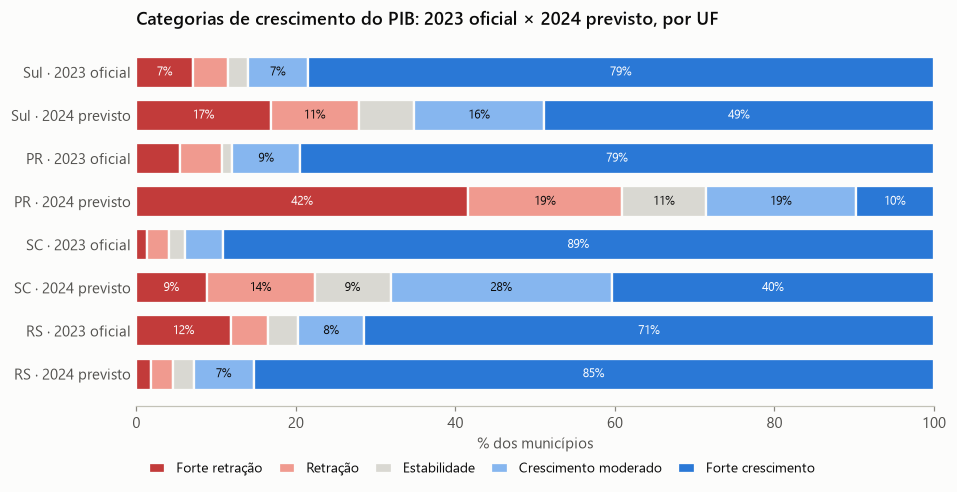

,Forte retração,Retração,Estabilidade,Crescimento moderado,Forte crescimento
Sul · 2023 oficial,7.100,4.400,2.500,7.500,78.500
Sul · 2024 previsto,16.900,11.000,7.000,16.300,48.900
PR · 2023 oficial,5.500,5.300,1.300,8.500,79.400
PR · 2024 previsto,41.600,19.300,10.500,18.800,9.800
SC · 2023 oficial,1.400,2.700,2.000,4.700,89.200
SC · 2024 previsto,8.800,13.600,9.500,27.800,40.300
RS · 2023 oficial,11.900,4.600,3.800,8.200,71.400
RS · 2024 previsto,1.800,2.800,2.600,7.400,85.300


In [9]:
def pct_categorias(codigos):
    return pd.Series(codigos).value_counts(normalize=True).reindex(range(len(CATS)), fill_value=0).to_numpy() * 100

cat_real_23 = m.codigos_categoria(dataset[dataset["ano"] == 2023].set_index("cod_ibge").loc[prev["cod_ibge"], "categoria_crescimento"])
linhas = {}
for regiao in ["Sul", "PR", "SC", "RS"]:
    filtro = np.ones(len(prev), bool) if regiao == "Sul" else (prev["uf"] == regiao).to_numpy()
    linhas[f"{regiao} · 2023 oficial"] = pct_categorias(cat_real_23[filtro])
    linhas[f"{regiao} · 2024 previsto"] = pct_categorias(prev["cat_2024"].to_numpy()[filtro])
tab_cat = pd.DataFrame(linhas, index=CATS).T
tab_cat.to_csv(DIR_RES / "previsao_2024_categorias_uf.csv")

contagem = pd.crosstab(prev["uf"], nome_cat(prev["cat_2024"]), margins=True, margins_name="Sul")
display(contagem)

fig, ax = plt.subplots(figsize=(8.8, 4.6))
viz.barras_categorias_por_ano(tab_cat, ax=ax,
                              titulo="Categorias de crescimento do PIB: 2023 oficial × 2024 previsto, por UF")
fig.tight_layout()
viz.salva_figura(fig, "fig_categorias_2024")
plt.show()
tab_cat.round(1)

### 5.3 Maiores altas e quedas previstas

Para entender as previsões extremas, mostramos também os principais sinais de 2024 que o modelo usa (notebook 03): o choque agrícola do município (`choque_pam`, variação do valor das lavouras como fração do PIB) e o da UF.

In [10]:
detalhe = prev.merge(alvo_2024[["cod_ibge", "choque_pam", "choque_soja", "choque_pam_uf", "cresc_pib_l1", "pam_valor_sobre_pib_l1"]],
                     on="cod_ibge")
colunas = ["municipio", "uf", "pib_l1", "pib_2024_prev", "cresc_2024_prev_pct", "choque_pam", "choque_soja",
           "pam_valor_sobre_pib_l1", "cresc_pib_l1"]
print("Maiores crescimentos previstos")
display(detalhe.nlargest(8, "cresc_2024_prev_pct")[colunas])
print("Maiores quedas previstas")
display(detalhe.nsmallest(8, "cresc_2024_prev_pct")[colunas])

Maiores crescimentos previstos


,municipio,uf,pib_l1,pib_2024_prev,cresc_2024_prev_pct,choque_pam,choque_soja,pam_valor_sobre_pib_l1,cresc_pib_l1
905,Itacurubi,RS,"114,342.000","233,036.287",103.806,1.390,1.244,1.788,0.236
747,Bossoroca,RS,"250,550.000","508,248.860",102.853,1.272,1.212,1.681,-0.041
777,Capão do Cipó,RS,"220,126.000","441,312.179",100.482,1.258,1.139,1.868,-0.228
919,Jóia,RS,"345,894.000","689,713.743",99.400,1.215,1.073,1.772,-0.271
1042,Rolador,RS,"91,405.000","154,994.647",69.569,0.829,0.775,1.357,0.014
1166,Unistalda,RS,"71,038.000","117,153.839",64.917,0.709,0.684,1.044,-0.023
1188,Vitória das Missões,RS,"89,071.000","145,195.907",63.011,0.755,0.684,1.070,0.106
934,Manoel Viana,RS,"303,342.000","488,358.356",60.993,0.753,0.645,1.314,-0.143


Maiores quedas previstas


,municipio,uf,pib_l1,pib_2024_prev,cresc_2024_prev_pct,choque_pam,choque_soja,pam_valor_sobre_pib_l1,cresc_pib_l1
185,Leópolis,PR,"226,118.000","148,392.599",-34.374,-0.548,-0.576,0.501,0.202
292,Quinta do Sol,PR,"314,953.000","223,360.287",-29.081,-0.458,-0.374,0.529,0.333
170,Janiópolis,PR,"336,925.000","243,498.717",-27.729,-0.366,-0.396,0.637,0.476
207,Mariluz,PR,"403,957.000","299,031.115",-25.975,-0.400,-0.313,0.450,0.451
106,Farol,PR,"255,636.000","190,847.676",-25.344,-0.270,-0.467,0.780,0.453
363,Sertaneja,PR,"465,712.000","354,723.814",-23.832,-0.339,-0.382,0.492,0.225
48,Cafezal do Sul,PR,"199,026.000","151,743.696",-23.757,-0.395,-0.255,0.334,0.359
295,Rancho Alegre,PR,"197,170.000","150,478.612",-23.681,-0.337,-0.370,0.481,0.123


In [11]:
# O choque agrícola explica as diferenças entre as UFs? Crescimento previsto mediano por faixa de choque
detalhe["faixa_choque"] = pd.cut(detalhe["choque_pam"], [-np.inf, -0.10, -0.02, 0.02, 0.10, np.inf],
                                 labels=["< -0,10", "-0,10 a -0,02", "-0,02 a 0,02", "0,02 a 0,10", "> 0,10"])
pd.crosstab(detalhe["faixa_choque"], detalhe["uf"], values=detalhe["cresc_2024_prev_pct"], aggfunc="median").round(1).join(
    detalhe.groupby("faixa_choque", observed=False).size().rename("municípios"))

,PR,RS,SC,municípios
faixa_choque,,,,
"< -0,10",-10.700,-5.000,-6.700,201
"-0,10 a -0,02",-1.000,1.000,1.800,269
"-0,02 a 0,02",4.900,7.600,7.300,418
"0,02 a 0,10",5.600,11.000,7.500,140
"> 0,10",13.100,24.500,10.800,163


## 6. Conclusões parciais

**Modelos da Etapa B**
- **Regressão:** o protocolo da Fase 4, refeito com validação 2019–2023, mantém o **Ensemble (Ridge + RF + LightGBM) com alvos a partir de 2016** (MAPE médio de 7,16%).
  - Só mudaram os hiperparâmetros do LightGBM: perda L1 e regularização `reg_lambda` = 5.
  - Em segundo lugar ficou o LightGBM sozinho, com 7,32% a partir de 2010.
- **Classificação:** é a escolha da seção 7 do notebook 04, a Regressão → categoria com o ensemble treinado com alvos a partir de 2013.
- **Coerência entre as duas previsões:**
  - 82% dos municípios recebem a mesma categoria pelos dois modelos, 16,5% diferem em uma categoria vizinha e só 1,2% em duas ou mais;
  - os crescimentos previstos pelas duas janelas diferem em mediana -0,1 ponto percentual;
  - as divergências se concentram perto dos limites das faixas.

**PIB de 2024 previsto**
- **Região Sul:** o PIB nominal passa de **R$ 1,83 trilhão para R$ 1,95 trilhão (+6,1%)**.
- **Por estado:**
  - **SC: +7,9%**;
  - **RS: +7,7%**, com o município mediano em +9,8%;
  - **PR: +3,1%**, mas com o **município mediano em -2,5%**. As grandes cidades, menos dependentes da lavoura, sustentam o agregado.
- **Incerteza:** o intervalo empírico de 80%, calculado com os erros da validação, vai de cerca de **±12% nos municípios até 10 mil habitantes** a -7% / +10% nos acima de 50 mil.

**Categorias de 2024 previstas**
- **Sul:** 49% dos municípios em "Forte crescimento", contra 79% em 2023, e 17% em "Forte retração".
- **PR, o caso mais negativo:** **42% em "Forte retração"** e só 10% em "Forte crescimento". As maiores quedas previstas ficam no norte e noroeste do estado, como Leópolis (-34%), Quinta do Sol e Janiópolis, todas com forte queda no valor da soja.
- **RS, o caso mais positivo:** **85% em "Forte crescimento"**. É a recuperação da safra depois da estiagem de 2023. As maiores altas previstas, perto de +100%, estão nas Missões (Itacurubi, Bossoroca, Capão do Cipó e Jóia), onde o valor das lavouras supera o próprio PIB.
- **SC:** fica no meio, com 40% em "Forte crescimento" e 28% em "Crescimento moderado".
- **O que explica as diferenças:** o choque agrícola. O crescimento mediano previsto vai de -11% (PR) a -5% (RS) nos municípios com choque abaixo de -0,10, e de +11% a +25% naqueles com choque acima de +0,10.

**Limitações das previsões de 2024**
- **Enchentes de maio de 2024 no RS:** nenhuma fonte municipal usada as registra. Municípios muito atingidos, como Eldorado do Sul (+11%), Roca Sales (+8%) e Muçum (+7%), estão previstos em "Forte crescimento", e o crescimento deles **provavelmente está superestimado**.
- **Viés da Etapa A:** o modelo subestimou o crescimento comum de 2023 em cerca de 3 pontos e previu menos "Forte crescimento" do que o real (729 municípios, contra 935). Se o mesmo acontecer em 2024, a participação de "Forte crescimento" pode estar subestimada.
- **Extremos são os menos confiáveis:** as altas e quedas extremas, de ±30% a +100%, dependem quase só do choque agrícola, e os municípios pequenos são os que mais erram.

**Para o relatório:** figura `fig_categorias_2024` e as tabelas `previsao_2024_agregado_uf.csv` e `previsao_2024_categorias_uf.csv`. As previsões estão em `data/predictions/previsoes_pib_2024.csv`, `previsoes_categoria_2024.csv` e `previsoes_2023_validacao.csv`.